# Tổng quan đồ án: Dự đoán tình trạng học tập của sinh viên

Lĩnh vực giáo dục. Phân loại sinh viên thành `Dropout`, `Enrolled`, `Graduate` bằng dataset UCI 697.

In [16]:
from pathlib import Path
import sys, re
from importlib.metadata import version
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src" / "config.py").exists():
    raise FileNotFoundError("Không tìm thấy src/config.py")
sys.path.insert(0, str(ROOT))

# Xác nhận các thư viện dùng trong notebook khớp requirements.txt.
pins = {}
for line in (ROOT / "requirements.txt").read_text(encoding="utf-8").splitlines():
    match = re.match(r"^([A-Za-z0-9_.-]+)==([^;\s]+)$", line.strip())
    if match:
        pins[match.group(1).lower().replace("_", "-")] = match.group(2)
used = ["numpy", "pandas", "scikit-learn", "matplotlib", "ipython"]
versions = pd.DataFrame([
    {"Thư viện": name, "requirements.txt": pins[name], "Đang chạy": version(name),
     "Khớp": pins[name] == version(name)} for name in used
])
display(versions)
if not versions["Khớp"].all():
    raise RuntimeError("Phiên bản thư viện không khớp requirements.txt")

from src import config
from src.data import load_data
print("Python:", sys.version.split()[0])

,Thư viện,requirements.txt,Đang chạy,Khớp
0,numpy,2.5.4,2.5.4,True
1,pandas,3.1.1,3.1.1,True
2,scikit-learn,1.9.1,1.9.1,True
3,matplotlib,3.11.2,3.11.2,True
4,ipython,9.18.1,9.18.1,True


Python: 3.12.10


## 1. Dataset

Nguồn: [UCI Machine Learning Repository — Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success). `Target` gồm ba trạng thái học tập.

,Chỉ tiêu,Giá trị
0,Số dòng,4424
1,Biến đầu vào,36
2,Số lớp,3
3,Giá trị thiếu,0


,Số sinh viên
Target,
Dropout,1421
Enrolled,794
Graduate,2209


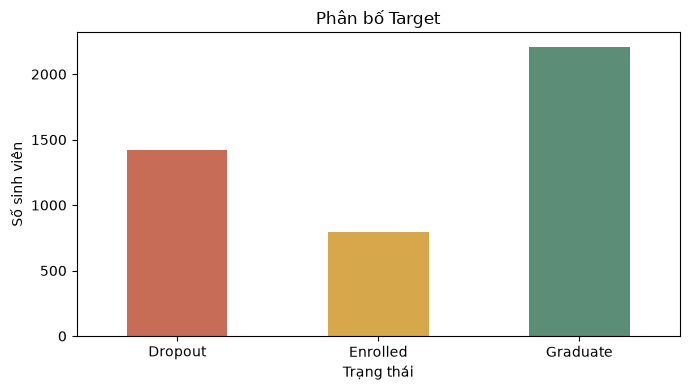

In [17]:
df = load_data()
counts = df[config.TARGET].value_counts().reindex(config.CLASSES)
display(pd.DataFrame({"Chỉ tiêu":["Số dòng","Biến đầu vào","Số lớp","Giá trị thiếu"],
                     "Giá trị":[len(df),df.shape[1]-1,df[config.TARGET].nunique(),int(df.isna().sum().sum())]}))
display(counts.rename("Số sinh viên").to_frame())
ax=counts.plot(kind="bar",color=["#c76d57","#d7a84b","#5c8d76"],figsize=(7,4))
ax.set(title="Phân bố Target",xlabel="Trạng thái",ylabel="Số sinh viên")
ax.tick_params(axis="x",rotation=0); plt.tight_layout(); plt.show()

`Graduate` là lớp đông nhất, `Enrolled` ít nhất. Macro-F1 và chỉ số theo lớp phù hợp hơn Accuracy đơn lẻ để nhận xét kết quả.

## 2. Thiết kế thực nghiệm

- A: thông tin nhập học; B: A + học kỳ 1; C: B + học kỳ 2.
- Chia phân tầng 80/20, seed 42; chọn cấu hình bằng Stratified 5-fold CV trên train, seed 42.
- Tiền xử lý nằm trong pipeline. Độ đo chính: Macro-F1; kèm Accuracy, balanced accuracy, Recall Dropout, F1 Enrolled và confusion matrix.
- So sánh holdout cuối dùng tập C.

In [19]:
display(pd.DataFrame({"Tập":list(config.FEATURE_SETS),
    "Số biến gốc":[len(config.FEATURE_SETS[k]) for k in config.FEATURE_SETS],
    "Thời điểm":["Nhập học","Sau học kỳ 1","Sau học kỳ 2"]}))

,Tập,Số biến gốc,Thời điểm
0,A,24,Nhập học
1,B,30,Sau học kỳ 1
2,C,36,Sau học kỳ 2


## 3. Mô hình

Repo có năm artifact cuối. KNN trong danh sách gợi ý chưa được triển khai; Gradient Boosting là mô hình bổ sung.

In [21]:
display(pd.DataFrame([
 ["Logistic Regression","models/lr_best.joblib","Có"],
 ["Decision Tree","models/dt_best.joblib","Có"],
 ["Random Forest","models/rf_best.joblib","Có"],
 ["SVM RBF","models/svm_best.joblib","Có"],
 ["Gradient Boosting","models/gb_best.joblib","Có"]
 ],columns=["Mô hình","Artifact","Trạng thái"]))

,Mô hình,Artifact,Trạng thái
0,Logistic Regression,models/lr_best.joblib,Có
1,Decision Tree,models/dt_best.joblib,Có
2,Random Forest,models/rf_best.joblib,Có
3,SVM RBF,models/svm_best.joblib,Có
4,Gradient Boosting,models/gb_best.joblib,Có


## 4. Kết quả tập C

Ghép CV evidence với metrics holdout đã lưu. Notebook không gọi `fit` hoặc `predict`.

In [22]:
cv_sources={"Logistic Regression":("reports/lr_cv_metrics.csv","LogisticRegression"),
 "Decision Tree":("reports/dt_cv_metrics.csv","DecisionTree"),
 "Random Forest":("reports/rf_cv_metrics.csv","RandomForest")}
cv_rows=[]
for name,(file,source_name) in cv_sources.items():
 table=pd.read_csv(ROOT/file)
 row=table.loc[table["model"].eq(source_name)&table["feature_set"].eq("C")].iloc[0]
 cv_rows.append({"Mô hình":name,"CV Macro-F1":row["f1_macro_mean"],"CV SD":row["f1_macro_std"]})
gb_svm=pd.read_csv(ROOT/"reports/sv4_rebuild_cv.csv")
for name,source_name in [("Gradient Boosting","GradientBoosting(best)"),("SVM RBF","SVM(best)")]:
 row=gb_svm.loc[gb_svm["model"].eq(source_name)&gb_svm["feature_set"].eq("C")].iloc[0]
 cv_rows.append({"Mô hình":name,"CV Macro-F1":row["f1_macro_mean"],"CV SD":row["f1_macro_std"]})
cv=pd.DataFrame(cv_rows)
h=pd.read_csv(ROOT/"reports/evaluation/holdout/metrics.csv")
h["Mô hình"]=h["model"].map({"LR":"Logistic Regression","DT":"Decision Tree","RF":"Random Forest","GB":"Gradient Boosting","SVM":"SVM RBF"})
results=cv.merge(h,on="Mô hình")[["Mô hình","CV Macro-F1","CV SD","f1_macro","accuracy","balanced_accuracy","recall_Dropout","f1_Enrolled"]].rename(columns={
 "f1_macro":"Holdout Macro-F1","accuracy":"Holdout Accuracy","balanced_accuracy":"Balanced accuracy",
 "recall_Dropout":"Recall Dropout","f1_Enrolled":"F1 Enrolled"})
display(results.round(4))

,Mô hình,CV Macro-F1,CV SD,Holdout Macro-F1,Holdout Accuracy,Balanced accuracy,Recall Dropout,F1 Enrolled
0,Logistic Regression,0.7170,0.0191,0.6817,0.7220,0.6922,0.6831,0.4861
1,Decision Tree,0.6823,0.0139,0.6410,0.7299,0.6311,0.6444,0.3610
2,Random Forest,0.7256,0.0143,0.7057,0.7469,0.7148,0.7113,0.5144
3,Gradient Boosting,0.7139,0.0119,0.6925,0.7605,0.6868,0.7500,0.4589
4,SVM RBF,0.7213,0.0113,0.7056,0.7412,0.7180,0.6796,0.5287


**Nhận xét:** RF đạt Holdout Macro-F1 0,7057; SVM đạt 0,7056, gần ngang nhau. GB có Accuracy 0,7605 và Recall Dropout 0,7500 cao nhất. F1 của lớp Enrolled thấp nhất trong cả năm mô hình (0,361–0,529). Holdout thấp hơn CV.

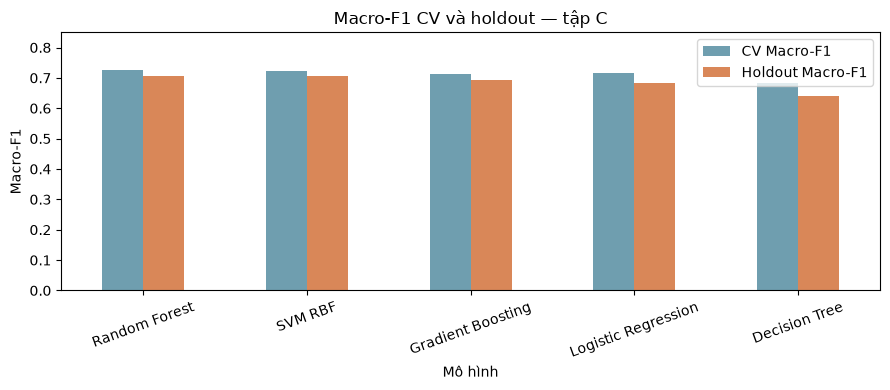

In [23]:
plot=results.sort_values("Holdout Macro-F1",ascending=False).set_index("Mô hình")[["CV Macro-F1","Holdout Macro-F1"]]
ax=plot.plot(kind="bar",figsize=(9,4),color=["#6f9eaf","#d98758"])
ax.set(title="Macro-F1 CV và holdout — tập C",ylabel="Macro-F1",ylim=(0,0.85))
ax.tick_params(axis="x",rotation=20); plt.tight_layout(); plt.show()

## 5. Confusion matrix đã lưu

Hàng là nhãn thật, cột là nhãn dự đoán. Bảng được đọc từ artifact đánh giá.

In [25]:
for model,label in [("RF","Random Forest"),("SVM","SVM RBF")]:
 print(label)
 display(pd.read_csv(ROOT/f"reports/evaluation/holdout/{model}_confusion.csv",index_col=0))

Random Forest


,pred_Dropout,pred_Enrolled,pred_Graduate
true_Dropout,202,57,25
true_Enrolled,30,98,31
true_Graduate,14,67,361


SVM RBF


,pred_Dropout,pred_Enrolled,pred_Graduate
true_Dropout,193,64,27
true_Enrolled,20,106,33
true_Graduate,13,72,357


## 6. Kết luận và giới hạn

RF và SVM gần ngang nhau theo Macro-F1; SVM có F1 Enrolled cao hơn. Lớp Enrolled vẫn khó dự đoán. Kết quả chỉ phản ánh dataset UCI này, chưa chứng minh khả năng khái quát sang trường khác.

Tài liệu: `README.md`, `docs/schema_dau_vao.md`, `docs/evaluation/decision_record.md`, `docs/evaluation/holdout_summary.md`.